# Multinomial and Bernoulli Naive Bayes

Same idea as `12_naive_bayes` (Bayes' rule + assume features are independent given the class), but for **discrete** features instead of continuous Gaussian ones — the standard choice for text.

| | Features | Likelihood of a sample | Absence is evidence? |
|---|---|---|---|
| **MultinomialNB** | counts (word counts, TF) | `Π p_j^(x_j)` | no — only what occurs counts |
| **BernoulliNB** | binary (word present / absent) | `Π p_j^(x_j) · (1 − p_j)^(1 − x_j)` | yes |

Both use **Laplace smoothing** (`alpha=1`): add `alpha` to every count so a word never seen in a class gets a small probability instead of 0, which would otherwise veto the whole class (`log 0 = −∞`).

Everything is done in log space (sums of logs, not products of tiny probabilities) to avoid underflow.

Rule of thumb: use Multinomial when word *frequency* matters (long documents), Bernoulli for short texts or when absence is informative.

## Usage

```python
# (the class is defined in the Implementation section below)

counts_model = MultinomialNB(alpha=1.0).fit(X_counts, y)
binary_model = BernoulliNB(alpha=1.0).fit((X_counts > 0).astype(float), y)
preds = counts_model.predict(X_new)
```

This notebook is self-contained: the explanation, the implementation, the visuals, the scikit-learn check and the tests are all here.

## Setup

In [1]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25, "axes.spines.top": False, "axes.spines.right": False})

## Implementation

The whole algorithm, as a plain Python class (numpy only).

In [2]:
import numpy as np


class _NaiveBayesBase:
    def __init__(self, alpha=1.0):
        self.alpha = alpha  # Laplace smoothing: pretend every feature was seen alpha extra times
        self.classes_ = None
        self.log_prior = None
        self.log_prob = None

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        self.classes_, y_enc = np.unique(y, return_inverse=True)
        self.log_prior = np.log(np.bincount(y_enc) / len(y_enc))
        self._fit_likelihood(X, y_enc)
        return self

    def predict(self, X):
        X = np.asarray(X, dtype=float)
        return self.classes_[np.argmax(self._joint_log_likelihood(X), axis=1)]


class MultinomialNB(_NaiveBayesBase):
    """For count features (word counts, histograms). P(feature j | class c) is the smoothed
    share of class c's total count that falls on feature j."""

    def _fit_likelihood(self, X, y_enc):
        counts = np.array([X[y_enc == c].sum(axis=0) for c in range(len(self.classes_))]) + self.alpha
        self.log_prob = np.log(counts / counts.sum(axis=1, keepdims=True))

    def _joint_log_likelihood(self, X):
        return X @ self.log_prob.T + self.log_prior  # a feature seen x times contributes x * log p


class BernoulliNB(_NaiveBayesBase):
    """For binary features (word present / absent). Unlike Multinomial, the *absence* of a
    feature is evidence too. Features must be 0/1."""

    def _fit_likelihood(self, X, y_enc):
        n_c = np.bincount(y_enc)
        ones = np.array([X[y_enc == c].sum(axis=0) for c in range(len(self.classes_))])
        self.log_prob = np.log((ones + self.alpha) / (n_c[:, None] + 2 * self.alpha))  # P(x_j = 1 | c)
        self.log_neg_prob = np.log(1 - np.exp(self.log_prob))  # P(x_j = 0 | c)

    def _joint_log_likelihood(self, X):
        return X @ self.log_prob.T + (1 - X) @ self.log_neg_prob.T + self.log_prior

## See it work

### 1. What it learned: per-class pixel profiles

Each digit image is 64 pixel counts. Multinomial NB learns, for each class, how likely each pixel is to be "on" (`P(pixel | digit)`). Averaging the training images per class shows exactly that profile.

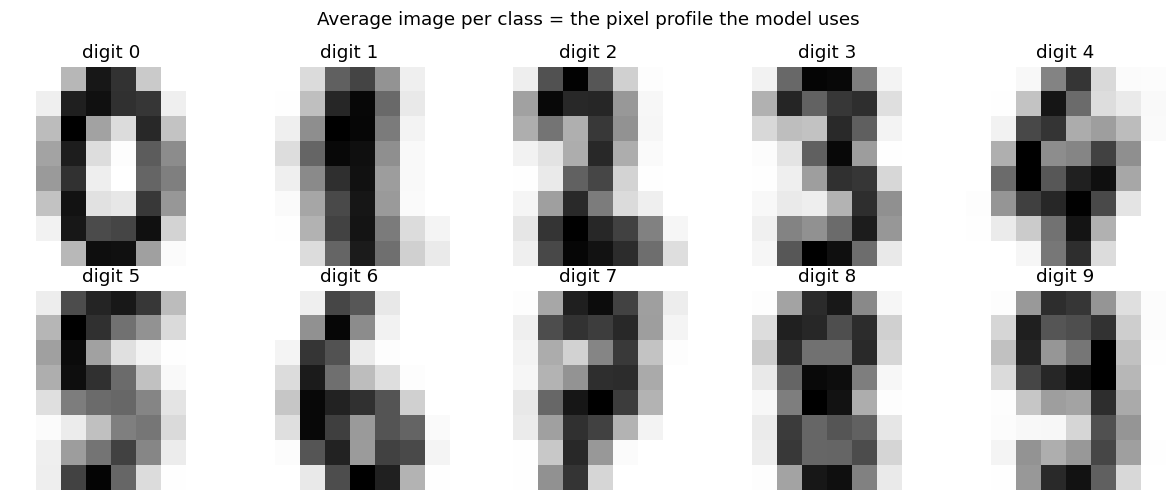

In [3]:
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split

digits = load_digits()
Xtr, Xte, ytr, yte = train_test_split(digits.data, digits.target, test_size=0.3, random_state=42)
fig, axes = plt.subplots(2, 5, figsize=(11, 4.6))
for c, ax in enumerate(axes.ravel()):
    ax.imshow(Xtr[ytr == c].mean(0).reshape(8, 8), cmap="gray_r"); ax.set_title(f"digit {c}"); ax.axis("off")
plt.suptitle("Average image per class = the pixel profile the model uses"); plt.tight_layout(); plt.show()

### 2. Where it gets confused

A confusion matrix: rows are the true digit, columns the prediction. The diagonal is correct; off-diagonal blocks show which digits are mistaken for which (here 8s and 9s with 1s and 5s).

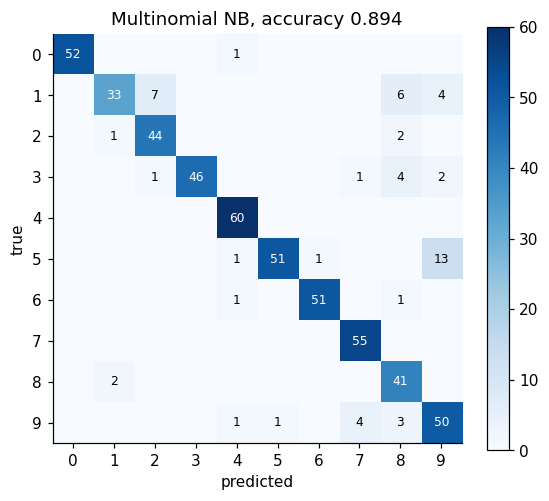

In [4]:
m = MultinomialNB().fit(Xtr, ytr)
pred = m.predict(Xte)
cm = np.zeros((10, 10), int)
for t, p in zip(yte, pred): cm[t, p] += 1
plt.figure(figsize=(6, 5)); plt.imshow(cm, cmap="Blues"); plt.colorbar()
for i in range(10):
    for j in range(10):
        if cm[i, j]: plt.text(j, i, cm[i, j], ha="center", va="center", color="w" if cm[i, j] > cm.max() / 2 else "k", fontsize=8)
plt.xticks(range(10)); plt.yticks(range(10)); plt.xlabel("predicted"); plt.ylabel("true"); plt.title(f"Multinomial NB, accuracy {(pred == yte).mean():.3f}"); plt.grid(False); plt.show()

### 3. Laplace smoothing

If a feature value never appears for a class in training, its probability is 0 and a single such feature vetoes the whole class (log 0). `alpha` adds a pseudo-count to every cell. Too little: brittle. Too much: it washes out the data.

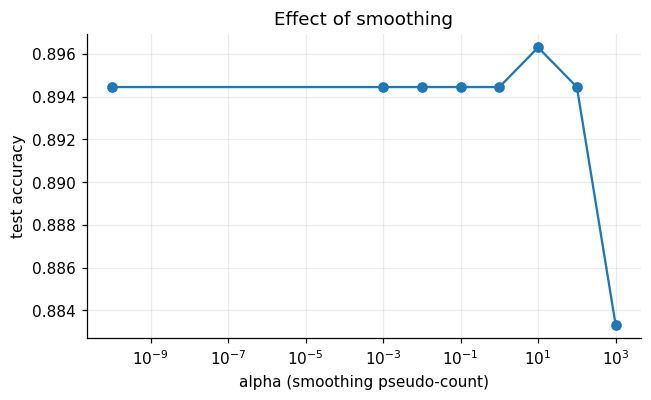

In [5]:
alphas = [1e-10, 1e-3, 1e-2, 0.1, 1, 10, 100, 1000]
acc = [(MultinomialNB(alpha=a).fit(Xtr, ytr).predict(Xte) == yte).mean() for a in alphas]
plt.figure(figsize=(6.5, 3.6)); plt.semilogx(alphas, acc, "o-"); plt.xlabel("alpha (smoothing pseudo-count)"); plt.ylabel("test accuracy"); plt.title("Effect of smoothing"); plt.show()

## Check against a reference implementation

Same data, same settings as scikit-learn (or scipy / the real library). The assertions fail if the two disagree.

In [6]:
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import BernoulliNB as SklearnBernoulliNB
from sklearn.naive_bayes import MultinomialNB as SklearnMultinomialNB

# digit images: pixel intensities 0..16 behave like counts; thresholded they become binary features
data = load_digits()
X_train, X_test, y_train, y_test = train_test_split(
    data.data, data.target, test_size=0.3, random_state=42
)

ours = MultinomialNB().fit(X_train, y_train)
theirs = SklearnMultinomialNB().fit(X_train, y_train)
print("Multinomial  test accuracy: ours=%.4f sklearn=%.4f"
      % ((ours.predict(X_test) == y_test).mean(), (theirs.predict(X_test) == y_test).mean()))
assert (ours.predict(X_test) == theirs.predict(X_test)).all()

Xb_train, Xb_test = (X_train > 8).astype(float), (X_test > 8).astype(float)
ours = BernoulliNB().fit(Xb_train, y_train)
theirs = SklearnBernoulliNB(binarize=None).fit(Xb_train, y_train)  # already binary
print("Bernoulli    test accuracy: ours=%.4f sklearn=%.4f"
      % ((ours.predict(Xb_test) == y_test).mean(), (theirs.predict(Xb_test) == y_test).mean()))
assert (ours.predict(Xb_test) == theirs.predict(Xb_test)).all()

Multinomial  test accuracy: ours=0.8944 sklearn=0.8944
Bernoulli    test accuracy: ours=0.8778 sklearn=0.8778


## Tests

Plain `assert` tests that check the invariants of the algorithm.

In [7]:
import numpy as np

# tiny "documents": columns = [free, money, meeting, report]
WORD_COUNTS = np.array(
    [[3, 2, 0, 0], [2, 3, 0, 1], [4, 1, 0, 0],   # spam: free / money
     [0, 0, 3, 2], [0, 1, 2, 3], [0, 0, 4, 1]],  # ham: meeting / report
    dtype=float,
)
LABELS = np.array(["spam", "spam", "spam", "ham", "ham", "ham"])


def test_multinomial_classifies_word_counts():
    model = MultinomialNB().fit(WORD_COUNTS, LABELS)
    assert (model.predict(WORD_COUNTS) == LABELS).all()
    assert model.predict(np.array([[5.0, 4.0, 0.0, 0.0], [0.0, 0.0, 5.0, 3.0]])).tolist() == ["spam", "ham"]


def test_bernoulli_classifies_presence_absence():
    X = (WORD_COUNTS > 0).astype(float)
    model = BernoulliNB().fit(X, LABELS)
    assert (model.predict(X) == LABELS).all()


def test_smoothing_handles_an_unseen_word():
    # "report" never appears in spam training docs: without smoothing P = 0 and log(0) = -inf
    X = np.array([[2.0, 1.0, 0.0], [3.0, 2.0, 0.0], [0.0, 1.0, 3.0], [0.0, 0.0, 2.0]])
    y = np.array([0, 0, 1, 1])
    model = MultinomialNB(alpha=1.0).fit(X, y)
    assert np.isfinite(model.log_prob).all()
    assert model.predict(np.array([[1.0, 1.0, 1.0]])).shape == (1,)

In [8]:
tests = [(name, fn) for name, fn in list(globals().items()) if name.startswith("test_") and callable(fn)]
for name, fn in tests:
    fn()
    print("PASS", name)
print(f"\nall {len(tests)} tests passed")

PASS test_multinomial_classifies_word_counts
PASS test_bernoulli_classifies_presence_absence
PASS test_smoothing_handles_an_unseen_word

all 3 tests passed


## Takeaways

- **Multinomial NB** is for counts (word frequencies, pixel intensities); **Bernoulli NB** is for binary present/absent features and also penalises the *absence* of features. Both are the standard fast baselines for text classification.
- **Everything in log space:** `argmax_c  log P(c) + Σ_f count_f · log θ_cf`; never multiply raw probabilities of hundreds of features.
- **Pitfalls:** independence assumption, zero counts (use smoothing, `alpha = 1` is Laplace), features should be non-negative.
- **Interview line:** *"Bayes' rule with independent features; counts per class give `θ`; add-one smoothing avoids zero probabilities."*